# 22｜扩散模型：从加噪到逐步生成

一张图像逐渐混入随机噪声，最后几乎看不出数字；反过来，能否从噪声一点点恢复出有结构的样本？这一课将两个问题拆开：先准确计算**前向加噪**，再训练网络估计其中的噪声，并用多步反向更新生成一维数据。

**本课成果 / Outcomes**

1. 从 $\beta_t$ 算出 $\alpha_t$ 和累计保留系数 $\bar\alpha_t$，画出信号逐渐衰减的过程。
2. 用同一幅手写数字直观看加噪；推导给定 $x_0$ 时直接采样 $x_t$ 的公式。
3. 对双峰一维数据训练一个噪声预测器，从随机噪声运行反向过程，比较生成分布与训练数据。

数字图来自 scikit-learn 内置的 8×8 `digits` 数据集；它与常见的 28×28 MNIST 是不同的数据集。最后训练的是一维玩具模型，用于把公式和代码对应起来。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.datasets import load_digits

torch.set_num_threads(1)
torch.manual_seed(22)
np.random.seed(22)
style()

## 1 每一步保留多少信号

设原始样本为 $x_0$，加噪一共 $T=50$ 步。第 $t$ 步的噪声强度为 $0<\beta_t<1$，定义 $\alpha_t=1-\beta_t$。这一步得到

$$x_t=\sqrt{\alpha_t}\,x_{t-1}+\sqrt{\beta_t}\,z_t,\qquad z_t\sim\mathcal N(0,I).$$

第一项带来上一时刻的信号，第二项是新加入的独立高斯噪声。$\beta_t$ 随时间组成的表叫做**噪声日程 / noise schedule**。为了直接从 $x_0$ 取样，定义保留系数的乘积

$$\bar\alpha_t=\prod_{s=1}^{t}\alpha_s.$$

下面数组使用 Python 的零起始索引：`beta[0]` 对应数学中的 $\beta_1$，`alpha_bar[t - 1]` 对应 $\bar\alpha_t$。线性日程是本课的选择；不同日程会改变各时刻的信噪比。

beta at first / last step: 0.0020000000949949026 0.11999999731779099
alpha_bar at first / last step: 0.9980000257492065 0.04153267666697502


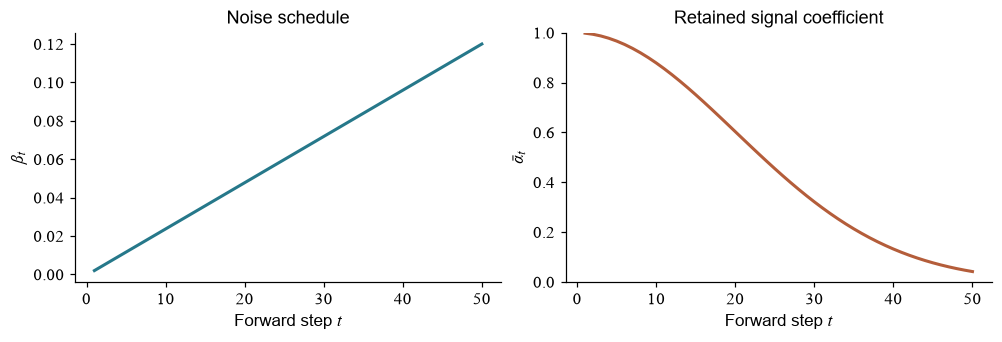

In [3]:
T = 50
beta = torch.linspace(.002, .12, T)
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)
print('beta at first / last step:', beta[0].item(), beta[-1].item())
print('alpha_bar at first / last step:', alpha_bar[0].item(), alpha_bar[-1].item())
fig, axes = plt.subplots(1, 2, figsize=(9, 3.0), layout='constrained')
steps = np.arange(1, T + 1)
axes[0].plot(steps, beta.numpy(), color='#26788A', lw=2)
axes[0].set(xlabel='Forward step $t$', ylabel=r'$\beta_t$', title='Noise schedule')
axes[1].plot(steps, alpha_bar.numpy(), color='#B45D3A', lw=2)
axes[1].set(xlabel='Forward step $t$', ylabel=r'$\bar{\alpha}_t$', title='Retained signal coefficient', ylim=(0, 1))
show(fig)

### 练习 diff01：计算累计保留系数

若两步的 $\alpha_1=0.9$、$\alpha_2=0.8$，将 $\bar\alpha_2$ 保存到 `ex_bar`。

In [4]:
ex_bar = None

In [5]:
# 填写上一格后，运行检查。
check('累计保留系数', ex_bar, .72)

待填写：累计保留系数


<details>
<summary>提示</summary>

把两步保留系数相乘。

</details>

<details>
<summary>参考答案</summary>

```python
ex_bar = .9 * .8
```

</details>

## 2 一次跳到任意加噪时刻

把上面的递推连续展开，各步独立的高斯噪声仍可合并成一个高斯随机变量。条件于固定的 $x_0$，直接采样得到

$$q(x_t\mid x_0)=\mathcal N\!\left(\sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t)I\right),\qquad
x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\quad\epsilon\sim\mathcal N(0,I).$$

均值是缩小后的原样本；方差 $1-\bar\alpha_t$ 控制噪声的分散程度。注意公式中的平方根：$\bar\alpha_t$ 是平方意义上的信号系数，而不是直接乘到 $x_0$ 的系数。

例如 $x_0=2$、$\bar\alpha_t=0.81$、$\epsilon=1$，第一项为 $1.8$，第二项为 $\sqrt{0.19}$。如果固定这一个 $\epsilon$，便能清楚地对比不同时刻的系数。训练时仍需重新独立采样噪声。

### 练习 diff02：手算一次加噪

计算上例的 $x_t$ 并保存到 `ex_xt`。

In [6]:
ex_xt = None

In [7]:
# 填写上一格后，运行检查。
check('前向样本', ex_xt, 1.8 + np.sqrt(.19))

待填写：前向样本


<details>
<summary>提示</summary>

将信号项与噪声项相加。

</details>

<details>
<summary>参考答案</summary>

```python
ex_xt = np.sqrt(.81) * 2 + np.sqrt(.19) * 1
```

</details>

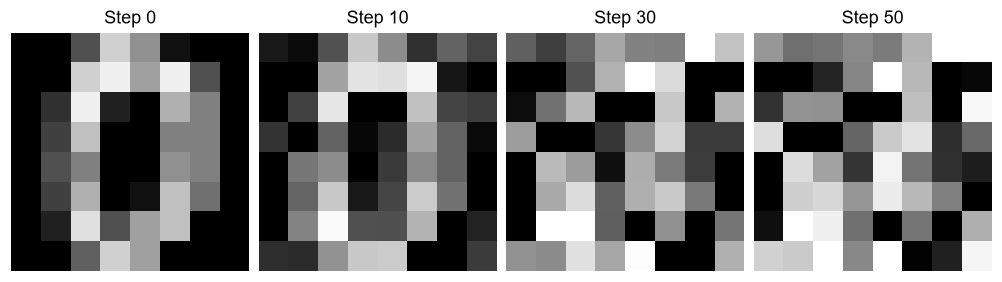

In [8]:
def forward_sample(x0, t_index, noise):
    """x0 and noise have the same shape; t_index is a zero-based schedule index."""
    retained = alpha_bar[t_index]
    return retained.sqrt() * x0 + (1. - retained).sqrt() * noise

image = torch.tensor(load_digits().images[0], dtype=torch.float32) / 8. - 1.
image_noise = torch.randn_like(image)
fig, axes = plt.subplots(1, 4, figsize=(9, 2.5), layout='constrained')
for ax, step in zip(axes, [0, 10, 30, 50]):
    sample = image if step == 0 else forward_sample(image, step - 1, image_noise)
    ax.imshow(sample.numpy(), cmap='gray', vmin=-1, vmax=1, interpolation='nearest')
    ax.set_title(f'Step {step}')
    ax.axis('off')
show(fig)

图中固定同一幅 8×8 数字和同一份噪声，只改变 $t$。灰度显示范围固定在 [−1,1]，范围外的值在显示时被截到边界；计算中的数值没有截断。由于各图共用噪声，它们用来比较系数变化，而不是展示相邻时刻独立增量的一条轨迹。

### 练习 diff03：从样本恢复已知噪声

若已知 $x_t$、$x_0$ 与 $\bar\alpha_t$，由前向公式解出 $\epsilon$。对 `ex_x0=1`、`ex_xt=1.5`、`ex_a=.64` 计算 `ex_noise`。

In [9]:
ex_x0, ex_xt, ex_a = 1., 1.5, .64
ex_noise = None

In [10]:
# 填写上一格后，运行检查。
check('恢复噪声', ex_noise, (1.5 - .8) / .6)

待填写：恢复噪声


<details>
<summary>提示</summary>

先减去信号项，再除以噪声项的系数。

</details>

<details>
<summary>参考答案</summary>

```python
ex_noise = (ex_xt - np.sqrt(ex_a) * ex_x0) / np.sqrt(1 - ex_a)
```

</details>

## 3 从给定时刻的带噪样本预测噪声

生成时我们没有原样本 $x_0$，因此不能用上一题的公式直接找回 $\epsilon$。训练一个网络 $\epsilon_\theta(x_t,t)$，输入当前带噪样本和时间，输出预测噪声。对每个训练样本随机选择 $t$，独立采样 $\epsilon$，用前向公式构造 $x_t$，最后最小化

$$L(\theta)=\mathbb E_{x_0,t,\epsilon}\left[\left\|\epsilon-\epsilon_\theta(x_t,t)\right\|^2\right].$$

这个均方误差的监督目标是我们自己加入的噪声。网络只有看到 $x_t$ 和 $t$ 才能学习估计，不会收到 $x_0$ 或真实噪声作为输入。训练示例使用一维双峰数据：先等概率选择中心 −2 或 +2，再加入标准差 0.25 的高斯扰动。

In [11]:
def sample_clean(n):
    signs = torch.where(torch.rand(n, 1) < .5, -1., 1.)
    return 2. * signs + .25 * torch.randn(n, 1)

class NoisePredictor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2, 64), nn.SiLU(),
                                 nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 1))

    def forward(self, x_t, t_index):
        # x_t: (B,1), t_index: (B,), output: (B,1)
        time = (t_index.float() + 1).unsqueeze(1) / T
        return self.net(torch.cat([x_t, time], dim=1))

predictor = NoisePredictor()
example_x = torch.tensor([[-1.], [1.], [2.]])
example_t = torch.tensor([0, 24, 49])
print('x_t, time index, predicted noise:', example_x.shape, example_t.shape,
      predictor(example_x, example_t).shape)

x_t, time index, predicted noise: torch.Size([3, 1]) torch.Size([3]) torch.Size([3, 1])


### 练习 diff04：确定模型输入形状

一个 batch 有 8 个一维样本；拼接归一化时间后，网络第一层输入的形状是什么？将元组保存到 `ex_shape`。

In [12]:
ex_shape = None

In [13]:
# 填写上一格后，运行检查。
check('网络输入形状', ex_shape, (8, 2))

待填写：网络输入形状


<details>
<summary>提示</summary>

每个样本有一个带噪值和一个时间值。

</details>

<details>
<summary>参考答案</summary>

```python
ex_shape = (8, 2)
```

</details>

下面的训练循环每步新采样一批 $x_0$、时间和噪声。`alpha_bar[t_index, None]` 的形状为 `(B,1)`，与一维样本逐项对齐。训练曲线是随机 batch 的损失，会波动；最后的生成质量需要另行检查。

mean loss, first 100 / last 100: 0.8035 0.4053


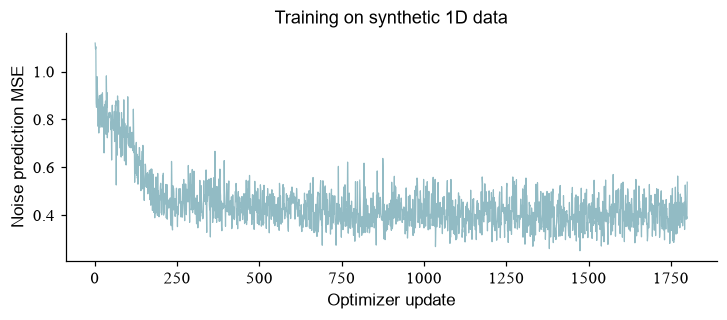

In [14]:
optimizer = torch.optim.Adam(predictor.parameters(), lr=.001)
losses = []
for update in range(1800):
    clean = sample_clean(256)
    t_index = torch.randint(T, (len(clean),))
    noise = torch.randn_like(clean)
    retained = alpha_bar[t_index, None]
    noisy = retained.sqrt() * clean + (1. - retained).sqrt() * noise
    predicted_noise = predictor(noisy, t_index)
    loss = ((predicted_noise - noise) ** 2).mean()
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
print('mean loss, first 100 / last 100:',
      round(np.mean(losses[:100]), 4), round(np.mean(losses[-100:]), 4))
fig, ax = plt.subplots(figsize=(6.5, 2.8), layout='constrained')
ax.plot(np.arange(1, len(losses) + 1), losses, lw=.8, alpha=.5, color='#26788A')
ax.set(xlabel='Optimizer update', ylabel='Noise prediction MSE', title='Training on synthetic 1D data')
show(fig)

### 练习 diff05：写出噪声预测损失

预测噪声 `[0., 2.]`，真实噪声 `[1., 1.]`，计算平均平方误差 `ex_loss`。

In [15]:
ex_loss = None

In [16]:
# 填写上一格后，运行检查。
check('噪声预测 MSE', ex_loss, 1.)

待填写：噪声预测 MSE


<details>
<summary>提示</summary>

先逐项相减、平方，再求平均。

</details>

<details>
<summary>参考答案</summary>

```python
ex_loss = np.mean((np.array([0., 2.]) - np.array([1., 1.])) ** 2)
```

</details>

## 4 从噪声逐步反推

从 $x_T\sim\mathcal N(0,I)$ 出发，每一步调用同一个预测器。下面使用 DDPM 形式的反向均值，并选择固定方差 $\beta_t$：

$$\mu_\theta(x_t,t)=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\right),\qquad
x_{t-1}=\begin{cases}\mu_\theta+\sqrt{\beta_t}\,z,&t>1,\\\mu_\theta,&t=1.\end{cases}$$

$z$ 在各步独立采样，最后一步不再加噪。每次网络估计当前时刻的噪声，均值公式将这个估计从样本中扣除，并按对应系数缩放；重复 50 次得到近似的 $x_0$。网络不必在一次调用中产生完整样本。

终点的 $\bar\alpha_T$ 只有约 0.04，原信号已大幅衰减；这里从标准正态初始化是生成模型的近似起点。这个短日程、有限训练与固定方差都可能造成生成分布和真实分布存在差距。

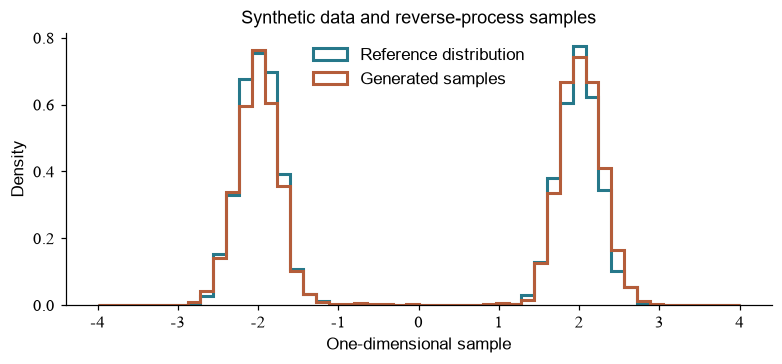

generated mean / std: 0.075 2.024


In [17]:
@torch.no_grad()
def generate(n):
    predictor.eval()
    x = torch.randn(n, 1)
    for i in range(T - 1, -1, -1):
        t_index = torch.full((n,), i, dtype=torch.long)
        estimated_noise = predictor(x, t_index)
        mean = (x - beta[i] / (1. - alpha_bar[i]).sqrt() * estimated_noise) / alpha[i].sqrt()
        x = mean + beta[i].sqrt() * torch.randn_like(x) if i > 0 else mean
    return x.squeeze(1)

torch.manual_seed(100)
reference = sample_clean(4000).squeeze(1).numpy()
generated = generate(4000).numpy()
fig, ax = plt.subplots(figsize=(7, 3.2), layout='constrained')
bins = np.linspace(-4, 4, 51)
ax.hist(reference, bins=bins, density=True, histtype='step', lw=2, label='Reference distribution', color='#26788A')
ax.hist(generated, bins=bins, density=True, histtype='step', lw=2, label='Generated samples', color='#B45D3A')
ax.set(xlabel='One-dimensional sample', ylabel='Density', title='Synthetic data and reverse-process samples')
ax.legend(frameon=False)
show(fig)
print('generated mean / std:', round(float(generated.mean()), 3), round(float(generated.std()), 3))

图中两条线分别统计独立参考样本与反向过程生成样本，纵轴为归一化密度。比较两侧峰的位置、宽度和相对高度；一次运行只给出一个有限样本的结果。

### 练习 diff06：理解最后一步

若当前已到 $t=1$，上面的采样规则使用均值 `mu=2.5`，还需要再加入随机噪声吗？将结果保存为 `ex_last`。

In [18]:
ex_last = None

In [19]:
# 填写上一格后，运行检查。
check('最后一步输出', ex_last, 2.5)

待填写：最后一步输出


<details>
<summary>提示</summary>

阅读分段公式中 $t=1$ 的分支。

</details>

<details>
<summary>参考答案</summary>

```python
ex_last = 2.5
```

</details>

## 5 自己做一次对照

固定模型结构与训练步数，改变日程的最后一个 $\beta_t$，记录 $\bar\alpha_T$、最后 100 次更新的平均损失以及生成样本直方图。重复不同随机种子，观察峰形变化；如果终点仍保留明显信号，从标准正态开始的近似会变得更值得检查。也可以固定日程，改变训练步数，比较损失和生成分布是否同步改善。

将这一维模型扩展到图像，需要让网络读取空间结构并输出与图像同形状的噪声，设计时间表示与更充分的训练和评价。本课的 8×8 图像仅用于前向可视化，一维模型没有训练图像生成。

## 带着问题读原文

[Denoising Diffusion Probabilistic Models (Ho et al., 2020)](https://arxiv.org/abs/2006.11239)

在论文中找到前向分布、噪声预测损失和反向更新。对照本课的固定方差选择，解释 $t=1$ 为什么不再注入噪声。